# Baseline Comparison 
**Files needed:** `LUAD.csv`, `LUSC.csv`, `GSE37745_expression.csv`, `GSE37745_clinical.csv`

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, balanced_accuracy_score

sns.set_theme(style="whitegrid")
DATA_DIR = "../data"
OUTPUT_DIR = "../results/baseline_comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)
for f in ["LUAD.csv", "LUSC.csv", "GSE37745_expression.csv", "GSE37745_clinical.csv"]:
    print(f"{f:28s} {'OK' if os.path.exists(os.path.join(DATA_DIR, f)) else 'NOT FOUND !!!'}")

N_REPEATS = 30
RUN_ALL_GENES_TCGA = True     # re-runs the all-gene model on the same 30 splits (~10-20 min).
                              # Set False to use the published numbers instead (faster).
TCGA_TUNED_C = 6.581          # from the original pipeline
GSE_TUNED_C = 0.05547         # from the GSE37745 replication notebook

IHC4 = ["NKX2-1", "NAPSA", "TP63", "KRT5"]
CORE13 = ["KRT5", "KRT6A", "KRT6B", "DSG3", "DSC3", "KRT14", "KRT13", "S100A7",
          "SERPINB13", "CALML3", "CLCA2", "GSTM1", "MUC5B"]

# Reference numbers already obtained earlier (used when a model is not re-run here)
REF = {"TCGA_all": (0.9569, 0.0173, 0.9884, 0.0080),      # acc, sd, auc, sd (original pipeline)
       "GSE_all": (0.9519, 0.0448, 0.9844, 0.0297),       # GSE37745 replication notebook
       "EXT_all": (0.9535, 0.9911)}                       # external validation notebook (acc, auc)

LUAD.csv                     OK
LUSC.csv                     OK
GSE37745_expression.csv      OK
GSE37745_clinical.csv        OK


## 2. Load data

In [2]:
def load_primary_tumor(path):
    e = pd.read_csv(path, index_col=0).T
    e = e[e.index.str.endswith("-01")]
    e.columns = [str(c).split("|")[0].upper() for c in e.columns]
    return e.loc[:, ~e.columns.duplicated()].astype(np.float32)

e_luad = load_primary_tumor(os.path.join(DATA_DIR, "LUAD.csv"))
e_lusc = load_primary_tumor(os.path.join(DATA_DIR, "LUSC.csv"))
genes = e_luad.columns.intersection(e_lusc.columns)
X_tcga = pd.concat([e_luad[genes], e_lusc[genes]])
y_tcga = np.array([0] * len(e_luad) + [1] * len(e_lusc))

X_gse = pd.read_csv(os.path.join(DATA_DIR, "GSE37745_expression.csv"), index_col=0).T
X_gse.columns = [str(c).upper() for c in X_gse.columns]
X_gse = X_gse.loc[:, ~X_gse.columns.duplicated()]
cg = pd.read_csv(os.path.join(DATA_DIR, "GSE37745_clinical.csv"), index_col=0)
cg = cg[cg["histology"].isin(["LUAD", "LUSC"])]
X_gse = X_gse.loc[cg.index].astype(np.float32)
y_gse = (cg["histology"] == "LUSC").astype(int).values

print(f"TCGA: {X_tcga.shape} | GSE37745: {X_gse.shape}")
for name, panel in [("IHC-4", IHC4), ("Core-13", CORE13)]:
    print(f"{name}: in TCGA {sum(g in X_tcga.columns for g in panel)}/{len(panel)}, "
          f"in GSE {sum(g in X_gse.columns for g in panel)}/{len(panel)}")

TCGA: (1017, 20502) | GSE37745: (172, 21653)
IHC-4: in TCGA 4/4, in GSE 4/4
Core-13: in TCGA 13/13, in GSE 13/13


## 3. Within-cohort evaluation — 30 random 80/10/10 splits (identical split rule to the pipeline)

In [3]:
def panel_model():
    # small panels: standardise inside the training fold, default C, balanced classes
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))

def all_gene_model(C):
    # identical to the original pipeline (no scaling, tuned C)
    return LogisticRegression(C=C, max_iter=3000, class_weight="balanced")

def metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y, pred), "AUC": roc_auc_score(y, p),
            "F1": f1_score(y, pred), "Balanced_Acc": balanced_accuracy_score(y, pred)}

def run_repeats(X, y, cohort, feature_sets):
    rows, t0 = [], time.time()
    for seed in range(N_REPEATS):
        idx = np.arange(len(y))
        tr, tmp = train_test_split(idx, test_size=0.2, random_state=seed, stratify=y)
        va, te = train_test_split(tmp, test_size=0.5, random_state=seed, stratify=y[tmp])
        for fs_name, (cols, make) in feature_sets.items():
            Xv = X[cols].values
            m = make().fit(Xv[tr], y[tr])
            rows.append({"cohort": cohort, "features": fs_name, "seed": seed,
                         **metrics(y[te], m.predict_proba(Xv[te])[:, 1])})
        if (seed + 1) % 5 == 0:
            print(f"  {cohort}: {seed+1}/{N_REPEATS} splits ({time.time()-t0:.0f}s)")
    return rows

ihc_t = [g for g in IHC4 if g in X_tcga.columns]; core_t = [g for g in CORE13 if g in X_tcga.columns]
ihc_g = [g for g in IHC4 if g in X_gse.columns];  core_g = [g for g in CORE13 if g in X_gse.columns]

fs_tcga = {"IHC-4": (ihc_t, panel_model), "Core-13": (core_t, panel_model)}
if RUN_ALL_GENES_TCGA:
    fs_tcga["All genes"] = (list(X_tcga.columns), lambda: all_gene_model(TCGA_TUNED_C))
fs_gse = {"IHC-4": (ihc_g, panel_model), "Core-13": (core_g, panel_model),
          "All genes": (list(X_gse.columns), lambda: all_gene_model(GSE_TUNED_C))}

rows = run_repeats(X_tcga, y_tcga, "TCGA", fs_tcga) + run_repeats(X_gse, y_gse, "GSE37745", fs_gse)
res = pd.DataFrame(rows)
res.to_csv(f"{OUTPUT_DIR}/within_cohort_raw.csv", index=False)

within = (res.groupby(["cohort", "features"])
          .agg(Acc_mean=("Accuracy", "mean"), Acc_sd=("Accuracy", "std"),
               AUC_mean=("AUC", "mean"), AUC_sd=("AUC", "std"),
               F1_mean=("F1", "mean"), BalAcc_mean=("Balanced_Acc", "mean")).round(4))
print(within.to_string())

  TCGA: 5/30 splits (17s)
  TCGA: 10/30 splits (32s)
  TCGA: 15/30 splits (47s)
  TCGA: 20/30 splits (62s)
  TCGA: 25/30 splits (74s)
  TCGA: 30/30 splits (90s)
  GSE37745: 5/30 splits (10s)
  GSE37745: 10/30 splits (17s)
  GSE37745: 15/30 splits (31s)
  GSE37745: 20/30 splits (41s)
  GSE37745: 25/30 splits (52s)
  GSE37745: 30/30 splits (63s)
                    Acc_mean  Acc_sd  AUC_mean  AUC_sd  F1_mean  BalAcc_mean
cohort   features                                                           
GSE37745 All genes    0.9500  0.0446    0.9848  0.0292   0.9347       0.9444
         Core-13      0.9556  0.0423    0.9818  0.0349   0.9410       0.9506
         IHC-4        0.9648  0.0449    0.9857  0.0319   0.9566       0.9660
TCGA     All genes    0.9572  0.0166    0.9883  0.0080   0.9565       0.9572
         Core-13      0.9484  0.0220    0.9885  0.0094   0.9472       0.9483
         IHC-4        0.9271  0.0209    0.9755  0.0135   0.9259       0.9271


### 3.1 Is the difference real? Paired Wilcoxon test across the 30 identical splits

In [4]:
test_rows = []
for cohort in res["cohort"].unique():
    sub = res[res["cohort"] == cohort]
    if "All genes" not in sub["features"].unique():
        continue
    base = sub[sub.features == "All genes"].sort_values("seed")
    for fs in ["IHC-4", "Core-13"]:
        other = sub[sub.features == fs].sort_values("seed")
        for metric in ["Accuracy", "AUC"]:
            d = base[metric].values - other[metric].values
            p = wilcoxon(base[metric].values, other[metric].values).pvalue if np.any(d != 0) else 1.0
            test_rows.append({"cohort": cohort, "comparison": f"All genes vs {fs}", "metric": metric,
                              "mean_difference": round(d.mean(), 4), "wilcoxon_p": p})
tests = pd.DataFrame(test_rows)
print(tests.to_string(index=False))
tests.to_csv(f"{OUTPUT_DIR}/paired_tests.csv", index=False)

  cohort           comparison   metric  mean_difference  wilcoxon_p
    TCGA   All genes vs IHC-4 Accuracy           0.0301    0.000017
    TCGA   All genes vs IHC-4      AUC           0.0128    0.000004
    TCGA All genes vs Core-13 Accuracy           0.0088    0.028496
    TCGA All genes vs Core-13      AUC          -0.0002    0.612006
GSE37745   All genes vs IHC-4 Accuracy          -0.0148    0.045500
GSE37745   All genes vs IHC-4      AUC          -0.0009    0.724662
GSE37745 All genes vs Core-13 Accuracy          -0.0056    0.816544
GSE37745 All genes vs Core-13      AUC           0.0030    0.305298


## 4. External test — train on TCGA, test on GSE37745 (per-cohort z-score, as in the external-validation notebook)

In [5]:
def zscore(df):
    return (df - df.mean()) / (df.std() + 1e-8)

ext_rows = []
for fs_name, panel in [("IHC-4", IHC4), ("Core-13", CORE13)]:
    cols = [g for g in panel if g in X_tcga.columns and g in X_gse.columns]
    m = LogisticRegression(max_iter=3000, class_weight="balanced").fit(zscore(X_tcga[cols]).values, y_tcga)
    p = m.predict_proba(zscore(X_gse[cols]).values)[:, 1]
    r = metrics(y_gse, p)
    rng = np.random.RandomState(0); boots = []
    for _ in range(1000):
        b = rng.randint(0, len(y_gse), len(y_gse))
        if len(np.unique(y_gse[b])) == 2:
            boots.append(metrics(y_gse[b], p[b]))
    b = pd.DataFrame(boots)
    ext_rows.append({"features": fs_name, "n_genes": len(cols), **{k: round(v, 4) for k, v in r.items()},
                     "Acc_95CI": f"{b.Accuracy.quantile(.025):.4f}-{b.Accuracy.quantile(.975):.4f}",
                     "AUC_95CI": f"{b.AUC.quantile(.025):.4f}-{b.AUC.quantile(.975):.4f}"})
ext_rows.append({"features": "All genes (from external-validation notebook)", "n_genes": "common genes",
                 "Accuracy": REF["EXT_all"][0], "AUC": REF["EXT_all"][1]})
ext = pd.DataFrame(ext_rows)
print(ext.to_string(index=False))
ext.to_csv(f"{OUTPUT_DIR}/external_TCGA_to_GSE.csv", index=False)

                                     features      n_genes  Accuracy    AUC     F1  Balanced_Acc      Acc_95CI      AUC_95CI
                                        IHC-4            4    0.9709 0.9884 0.9624        0.9707 0.9419-0.9942 0.9713-0.9987
                                      Core-13           13    0.9535 0.9763 0.9412        0.9565 0.9186-0.9826 0.9487-0.9964
All genes (from external-validation notebook) common genes    0.9535 0.9911    NaN           NaN           NaN           NaN


## 5. Final table 

Feature set   TCGA Acc %        TCGA AUC GSE37745 Acc %    GSE37745 AUC External Acc % External AUC
      IHC-4 92.71 ± 2.09 0.9755 ± 0.0135   96.48 ± 4.49 0.9857 ± 0.0319          97.09       0.9884
    Core-13 94.84 ± 2.20 0.9885 ± 0.0094   95.56 ± 4.23 0.9818 ± 0.0349          95.35       0.9763
  All genes 95.72 ± 1.66 0.9883 ± 0.0080   95.00 ± 4.46 0.9848 ± 0.0292          95.35       0.9911

* = reference value from the earlier notebook (not re-run here)


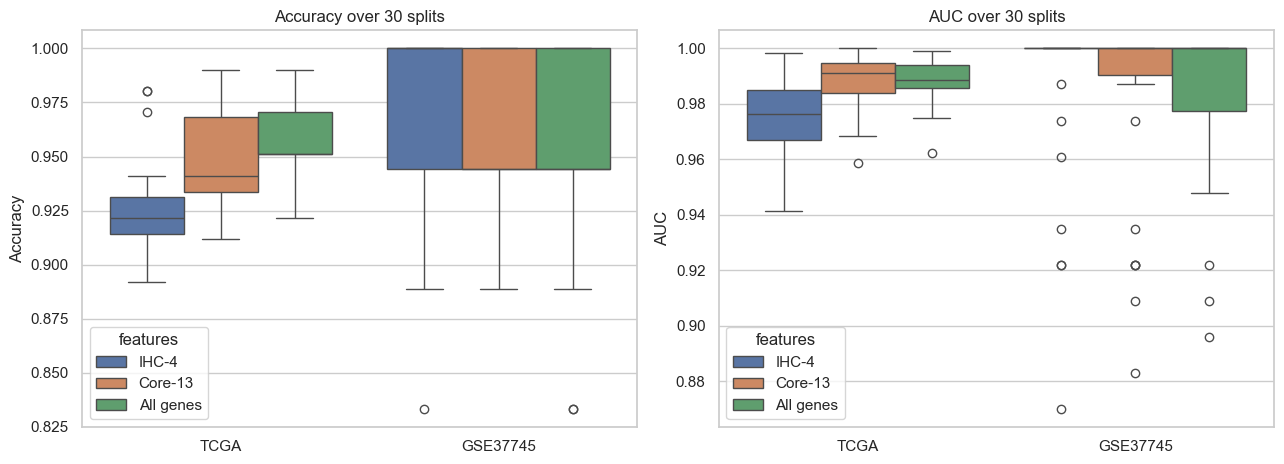

Saved in: results_baseline_comparison/


In [6]:
def fmt(m, s):
    return f"{m*100:.2f} ± {s*100:.2f}"

table = []
for fs in ["IHC-4", "Core-13", "All genes"]:
    row = {"Feature set": fs}
    for cohort in ["TCGA", "GSE37745"]:
        key = (cohort, fs)
        if key in within.index:
            w = within.loc[key]
            row[f"{cohort} Acc %"] = fmt(w.Acc_mean, w.Acc_sd)
            row[f"{cohort} AUC"] = f"{w.AUC_mean:.4f} ± {w.AUC_sd:.4f}"
        else:
            r = REF["TCGA_all"] if cohort == "TCGA" else REF["GSE_all"]
            row[f"{cohort} Acc %"] = fmt(r[0], r[1]) + " *"
            row[f"{cohort} AUC"] = f"{r[2]:.4f} ± {r[3]:.4f} *"
    e = ext[ext.features.str.startswith(fs)].iloc[0]
    row["External Acc %"] = f"{e.Accuracy*100:.2f}"
    row["External AUC"] = f"{e.AUC:.4f}"
    table.append(row)
final = pd.DataFrame(table)
pd.set_option("display.width", 200)
print(final.to_string(index=False))
print("\n* = reference value from the earlier notebook (not re-run here)")
final.to_csv(f"{OUTPUT_DIR}/baseline_comparison_table.csv", index=False)

plot = res.copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axes, ["Accuracy", "AUC"]):
    sns.boxplot(data=plot, x="cohort", y=metric, hue="features", ax=ax,
                hue_order=[h for h in ["IHC-4", "Core-13", "All genes"] if h in plot.features.unique()])
    ax.set_title(f"{metric} over {N_REPEATS} splits"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/baseline_comparison.png", dpi=150); plt.show()
print(f"Saved in: {OUTPUT_DIR}/")